# 🚀 Huấn Luyện Các Biến Thể PSO Tối Ưu Siêu Tham Số Mạng Nơ-ron (MLP)
Notebook này tập trung **toàn bộ mã nguồn định nghĩa và huấn luyện** 15 biến thể PSO (Particle Swarm Optimization) để tối ưu siêu tham số cho mạng nơ-ron đa tầng (MLPClassifier) trên bộ dữ liệu **Bank Marketing**.

Sau mỗi lượt huấn luyện, toàn bộ trạng thái và kết quả tối ưu (`gbest_pos`, `cv_score`, `convergence`, `history`, ...) được tự động lưu vào thư mục `../results/checkpoints/<algorithm>.pkl`.
Các kết quả này sau đó sẽ được nạp và kiểm thử độc lập trong file **`PSO_NeuralNetwork_Test.ipynb`**.


## 📦 1. Cài đặt và Khai báo Thư viện


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score, train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import time

print('Tất cả thư viện đã sẵn sàng!')
print(f'   NumPy  : {np.__version__}')
print(f'   Pandas : {pd.__version__}')

✅ Tất cả thư viện đã sẵn sàng!
   NumPy  : 2.4.6
   Pandas : 3.0.3


## 📊 2. Tải và Tiền xử lý Dữ liệu


      THÔNG TIN BỘ DỮ LIỆU BANK MARKETING
  Số mẫu       : 11162
  Số đặc trưng : 42 (sau One-Hot Encoding)
  Số lớp       : 2 (Gửi:1, Không:0)
  Phân phối    : {np.int64(0): np.int64(5873), np.int64(1): np.int64(5289)}


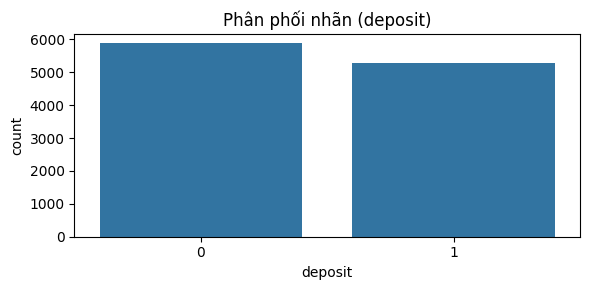

In [3]:
import seaborn as sns

df = pd.read_csv('../data/raw/bank.csv')
df['deposit'] = df['deposit'].map({'yes': 1, 'no': 0})
cat_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

X = df_encoded.drop('deposit', axis=1).values
y = df_encoded['deposit'].values

print('='*55)
print('      THÔNG TIN BỘ DỮ LIỆU BANK MARKETING')
print('='*55)
print(f'  Số mẫu       : {X.shape[0]}')
print(f'  Số đặc trưng : {X.shape[1]} (sau One-Hot Encoding)')
print(f'  Số lớp       : {len(np.unique(y))} (Gửi:1, Không:0)')
print(f'  Phân phối    : {dict(zip(*np.unique(y, return_counts=True)))}')
print('='*55)

plt.figure(figsize=(6, 3))
sns.countplot(data=df, x='deposit')
plt.title('Phân phối nhãn (deposit)')
plt.tight_layout()
plt.show()

In [ ]:
RANDOM_SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print('Tiền xử lý hoàn tất')
print(f'   Train : {X_train_sc.shape[0]} mẫu')
print(f'   Test  : {X_test_sc.shape[0]} mẫu')

✅ Tiền xử lý hoàn tất
   Train : 8929 mẫu
   Test  : 2233 mẫu


## 🔧 3. Định nghĩa Không gian tìm kiếm 3D & Hàm Fitness


In [ ]:
LOW  = np.array([16,  -4.0, -5.0])
HIGH = np.array([256, -1.0, -1.0])
DIM  = 3

def decode_position(x):
    n_neurons = int(np.clip(round(x[0]), 16, 256))
    lr        = float(10 ** np.clip(x[1], -4.0, -1.0))
    alpha     = float(10 ** np.clip(x[2], -5.0, -1.0))
    return n_neurons, lr, alpha

def fitness_single(x, X_tr, y_tr, cv_obj, seed):
    
    n_neurons, lr, alpha = decode_position(x)
    model = MLPClassifier(
        hidden_layer_sizes=(n_neurons, n_neurons),
        activation='relu',
        learning_rate_init=lr,
        alpha=alpha,
        max_iter=500,
        random_state=seed,
        early_stopping=True,
        n_iter_no_change=15
    )
    scores = cross_val_score(model, X_tr, y_tr, cv=cv_obj,
                             scoring='accuracy', n_jobs=-1)
    return scores.mean()

def fitness_averaged(x, X_tr, y_tr, cv_obj, seed, k=3):
    
    scores_all = []
    for run in range(k):
        n_neurons, lr, alpha = decode_position(x)
        model = MLPClassifier(
            hidden_layer_sizes=(n_neurons, n_neurons),
            activation='relu',
            learning_rate_init=lr,
            alpha=alpha,
            max_iter=500,
            random_state=seed + run, 
            early_stopping=True,
            n_iter_no_change=15
        )
        s = cross_val_score(model, X_tr, y_tr, cv=cv_obj,
                            scoring='accuracy', n_jobs=-1)
        scores_all.append(s.mean())
    return np.mean(scores_all)

print('Không gian tìm kiếm (3 chiều):')
print(f'   x[0] = n_neurons    ∈ [16, 256]')
print(f'   x[1] = log10(lr)    ∈ [-4, -1]  →  lr    ∈ [0.0001, 0.1]')
print(f'   x[2] = log10(alpha) ∈ [-5, -1]  →  alpha ∈ [0.00001, 0.1]')

✅ Không gian tìm kiếm (3 chiều):
   x[0] = n_neurons    ∈ [16, 256]
   x[1] = log10(lr)    ∈ [-4, -1]  →  lr    ∈ [0.0001, 0.1]
   x[2] = log10(alpha) ∈ [-5, -1]  →  alpha ∈ [0.00001, 0.1]


## 🔵 1. Thuật toán PSO gốc (Standard PSO)
- **Cơ chế:** Vận tốc và vị trí chuẩn của Kennedy & Eberhart (1995) với quán tính $w = 0.7$, hệ số gia tốc $c_1 = c_2 = 1.5$.
- **Không gian 3D:** $x = [\text{n\_neurons}, \log_{10}(\text{lr}), \log_{10}(\alpha)]$.
- **Mục tiêu:** Tối đa hóa 5-fold CV Accuracy trên tập Train.


In [ ]:
def run_standard_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w=0.7,       
    n1=1.5,      
    n2=1.5,      
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🔵 Standard PSO | w={w} (cố định) | n1={n1}, n2={n2}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = (
            w  * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)


gbest_std, cv_std, conv_std, hist_std = run_standard_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w=0.7, n1=1.5, n2=1.5,
    seed=RANDOM_SEED
)
n_std, lr_std, al_std = decode_position(gbest_std)
print(f'\n  Best: neurons={n_std}, lr={lr_std:.5f}, alpha={al_std:.6f}')
print(f'  CV Accuracy: {cv_std:.4f}')

In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_std,
    'cv_score':    cv_std,
    'convergence': conv_std,
    'history':     hist_std
}, '../results/checkpoints/standard_pso.pkl')

print('✅ Đã lưu kết quả Train Standard PSO tại: ../results/checkpoints/standard_pso.pkl')


## 🟢 2. PSO với Linear Decay Inertia Weight
- **Cơ chế:** Trọng số quán tính $w$ giảm tuyến tính từ $w_{\text{start}} = 0.9 \to w_{\text{end}} = 0.4$.
- **Mục tiêu:** Cân bằng giữa khám phá (Exploration - đầu quá trình) và khai thác (Exploitation - cuối quá trình).


In [ ]:
def run_pso_linear_decay(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w_start=0.9,  
    w_end=0.4,    
    n1=1.5,
    n2=1.5,
    v_max_ratio=0.2,
    seed=42
):
    
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    w_history   = []  

    print(f'🟢 PSO + Linear Decay w | w_start={w_start} → w_end={w_end}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        w_current = w_start - (w_start - w_end) / n_iter * it
        w_history.append(w_current)

        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al, 'w': w_current})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = (
            w_current * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | w={w_current:.3f} | gbest={gbest_score:.4f} | '
              f'neurons={n:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    df_hist = pd.DataFrame(history)
    return gbest_pos, gbest_score, convergence, df_hist, w_history


gbest_ld, cv_ld, conv_ld, hist_ld, w_hist_ld = run_pso_linear_decay(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w_start=0.9, w_end=0.4,
    n1=1.5, n2=1.5,
    seed=RANDOM_SEED
)
n_ld, lr_ld, al_ld = decode_position(gbest_ld)
print(f'\n  Best: neurons={n_ld}, lr={lr_ld:.5f}, alpha={al_ld:.6f}')
print(f'  CV Accuracy: {cv_ld:.4f}')

🟢 PSO + Linear Decay w | w_start=0.9 → w_end=0.4
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | w=0.900 | gbest=0.8438 | neurons=203, lr=0.00038 | [35s]
  Iter  2/20 | w=0.875 | gbest=0.8452 | neurons=218, lr=0.00579 | [78s]
  Iter  3/20 | w=0.850 | gbest=0.8452 | neurons=218, lr=0.00579 | [121s]
  Iter  4/20 | w=0.825 | gbest=0.8452 | neurons=218, lr=0.00579 | [169s]
  Iter  5/20 | w=0.800 | gbest=0.8452 | neurons=218, lr=0.00579 | [213s]
  Iter  6/20 | w=0.775 | gbest=0.8452 | neurons=214, lr=0.00678 | [253s]
  Iter  7/20 | w=0.750 | gbest=0.8457 | neurons=200, lr=0.00047 | [296s]
  Iter  8/20 | w=0.725 | gbest=0.8457 | neurons=200, lr=0.00047 | [342s]
  Iter  9/20 | w=0.700 | gbest=0.8457 | neurons=200, lr=0.00047 | [404s]
  Iter 10/20 | w=0.675 | gbest=0.8457 | neurons=200, lr=0.00047 | [468s]
  Iter 11/20 | w=0.650 | gbest=0.8457 | neurons=200, lr=0.00047 | [519s]
  Iter 12/20 | w=0.625 | gbest=0.8459 | neurons=196, lr=0

In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_ld,
    'cv_score':    cv_ld,
    'convergence': conv_ld,
    'history':     hist_ld,
    'w_history':   w_hist_ld
}, '../results/checkpoints/linear_decay_pso.pkl')

print('✅ Đã lưu kết quả Train Linear Decay PSO tại: ../results/checkpoints/linear_decay_pso.pkl')


## 🟡 3. PSO với Fitness Averaging
- **Cơ chế:** Đánh giá điểm thích nghi của mỗi hạt qua $k=3$ lần chạy với các hạt giống ngẫu nhiên khác nhau rồi lấy trung bình.
- **Mục tiêu:** Giảm thiểu độ nhiễu (stochastic variance) của quá trình khởi tạo trọng số MLP.


In [ ]:
def run_pso_fitness_avg(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w_start=0.9, w_end=0.4,
    n1=1.5, n2=1.5,
    v_max_ratio=0.2,
    k_avg=3,     
    seed=42
):
    
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟡 PSO + Fitness Averaging (k={k_avg}) | w_start={w_start} → w_end={w_end}')
    print(f'   {n_particles} particles × {n_iter} iterations | tổng fitness calls ≈ {n_particles*n_iter*k_avg}')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        w_current = w_start - (w_start - w_end) / n_iter * it

        for i in range(n_particles):
            score = fitness_averaged(positions[i], X_tr, y_tr, cv_obj, seed, k=k_avg)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = (
            w_current * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | w={w_current:.3f} | gbest={gbest_score:.4f} | '
              f'neurons={n:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)


gbest_fa, cv_fa, conv_fa, hist_fa = run_pso_fitness_avg(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w_start=0.9, w_end=0.4,
    n1=1.5, n2=1.5,
    k_avg=3,
    seed=RANDOM_SEED
)
n_fa, lr_fa, al_fa = decode_position(gbest_fa)
print(f'\n  Best: neurons={n_fa}, lr={lr_fa:.5f}, alpha={al_fa:.6f}')
print(f'  CV Accuracy: {cv_fa:.4f}')

🟡 PSO + Fitness Averaging (k=3) | w_start=0.9 → w_end=0.4
   12 particles × 20 iterations | tổng fitness calls ≈ 720
────────────────────────────────────────────────────────────
  Iter  1/20 | w=0.900 | gbest=0.8423 | neurons=124, lr=0.00130 | [111s]
  Iter  2/20 | w=0.875 | gbest=0.8435 | neurons=173, lr=0.00043 | [207s]
  Iter  3/20 | w=0.850 | gbest=0.8440 | neurons=163, lr=0.00086 | [307s]
  Iter  4/20 | w=0.825 | gbest=0.8440 | neurons=163, lr=0.00086 | [449s]
  Iter  5/20 | w=0.800 | gbest=0.8440 | neurons=163, lr=0.00086 | [597s]
  Iter  6/20 | w=0.775 | gbest=0.8449 | neurons=162, lr=0.00048 | [746s]
  Iter  7/20 | w=0.750 | gbest=0.8449 | neurons=162, lr=0.00048 | [909s]
  Iter  8/20 | w=0.725 | gbest=0.8449 | neurons=162, lr=0.00048 | [1080s]
  Iter  9/20 | w=0.700 | gbest=0.8449 | neurons=162, lr=0.00048 | [1248s]
  Iter 10/20 | w=0.675 | gbest=0.8449 | neurons=162, lr=0.00048 | [1402s]
  Iter 11/20 | w=0.650 | gbest=0.8449 | neurons=162, lr=0.00048 | [1539s]
  Iter 12/20 | 

In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_fa,
    'cv_score':    cv_fa,
    'convergence': conv_fa,
    'history':     hist_fa
}, '../results/checkpoints/fitness_avg_pso.pkl')

print('✅ Đã lưu kết quả Train Fitness Averaging PSO tại: ../results/checkpoints/fitness_avg_pso.pkl')


## 🟠 4. Constriction-type PSO (CPSO)
- **Cơ chế:** Áp dụng hệ số co hẹp Clerc & Kennedy (2002) với $\phi = \eta_1 + \eta_2 = 4.1 > 4$ và $K = \frac{2}{|2 - \phi - \sqrt{\phi^2 - 4\phi}|} \approx 0.729$.
- **Mục tiêu:** Đảm bảo toán học về sự hội tụ ổn định của quỹ đạo các hạt mà không cần clamp vận tốc thủ công.


In [ ]:
def compute_constriction_factor(n1, n2):
    """
    Tính Constriction Factor K — Equation (5) từ Meissner et al. 2006.
    Yêu cầu: phi = n1 + n2 > 4
    """
    phi = n1 + n2
    if phi <= 4:
        raise ValueError(f'φ = n1 + n2 = {phi} phải > 4 để K có nghĩa (Eq.6)')
    K = 2.0 / abs(2 - phi - np.sqrt(phi**2 - 4*phi))
    return K


def run_cpso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    n1=2.05,     
    n2=2.05,     
    seed=42
):
    """
    Constriction-type PSO (CPSO) — Equations (4)(5)(6) từ Meissner et al. 2006.
    Không dùng Vmax riêng vì K đã kiểm soát vận tốc.
    """
    K      = compute_constriction_factor(n1, n2)
    phi    = n1 + n2
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟠 CPSO | n1={n1}, n2={n2} | φ={phi:.2f} | K={K:.4f}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = K * (
            velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        positions = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | K={K:.4f} | gbest={gbest_score:.4f} | '
              f'neurons={n:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), K


gbest_cp, cv_cp, conv_cp, hist_cp, K_val = run_cpso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    n1=2.05, n2=2.05,
    seed=RANDOM_SEED
)
n_cp, lr_cp, al_cp = decode_position(gbest_cp)
print(f'\n  Best: neurons={n_cp}, lr={lr_cp:.5f}, alpha={al_cp:.6f}')
print(f'  CV Accuracy: {cv_cp:.4f}')

🟠 CPSO | n1=2.05, n2=2.05 | φ=4.10 | K=0.7298
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | K=0.7298 | gbest=0.8438 | neurons=203, lr=0.00038 | [50s]
  Iter  2/20 | K=0.7298 | gbest=0.8438 | neurons=203, lr=0.00038 | [108s]
  Iter  3/20 | K=0.7298 | gbest=0.8438 | neurons=203, lr=0.00038 | [174s]
  Iter  4/20 | K=0.7298 | gbest=0.8438 | neurons=203, lr=0.00038 | [320s]
  Iter  5/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [480s]
  Iter  6/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [647s]
  Iter  7/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [803s]
  Iter  8/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [994s]
  Iter  9/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [1201s]
  Iter 10/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [1393s]
  Iter 11/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [1604s]
  Iter 12/20 | K=0.7298 | gbest=0.8468 | neur

In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_cp,
    'cv_score':    cv_cp,
    'convergence': conv_cp,
    'history':     hist_cp,
    'K_val':       K_val
}, '../results/checkpoints/cpso.pkl')

print('✅ Đã lưu kết quả Train CPSO tại: ../results/checkpoints/cpso.pkl')


## 🟣 5. Fractional-Order PSO (FO-PSO)
- **Cơ chế:** Áp dụng đạo hàm bậc phân số Grünwald-Letnikov với $\alpha = 0.6$ và bộ nhớ vận tốc $r = 4$ bước quá khứ.
- **Mục tiêu:** Giữ lại ký ức dài hạn về động lượng để bầy đàn không bị đổi hướng đột ngột.


In [ ]:
def run_fopso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    alpha=0.6,    # Hệ số đạo hàm bậc phân số
    r=4,          # Số lượng v_t trong quá khứ được giữ lại
    n1=1.5, n2=1.5,
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    # Khởi tạo bộ nhớ cho các vận tốc trong quá khứ: v_{t}, v_{t-1}, v_{t-2}, v_{t-3}
    v_memory = np.zeros((r, n_particles, DIM))
    v_memory[0] = velocities

    # Tính các hệ số trọng lượng phân số (Fractional Coefficients)
    c_w = np.zeros(r)
    c_w[0] = alpha
    for k in range(1, r):
        c_w[k] = c_w[k-1] * (k - alpha) / (k + 1)

    print(f'🟣 FO-PSO | alpha: {alpha} | r: {r} | c_w: {np.round(c_w, 4)}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    import time
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)  # General fitness
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        
        # Tính thành phần quán tính dựa trên đạo hàm bậc phân số
        inertial_velocity = np.zeros((n_particles, DIM))
        for k in range(r):
            inertial_velocity += c_w[k] * v_memory[k]
        
        velocities = (
            inertial_velocity
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        
        # Cập nhật bộ nhớ vận tốc (dịch chuyển các vận tốc cũ xuống)
        for k in range(r - 1, 0, -1):
            v_memory[k] = v_memory[k-1]
        v_memory[0] = velocities

        positions  = np.clip(positions + velocities, LOW, HIGH)
        convergence.append(gbest_score)
        
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy thử nghiệm thuật toán FO-PSO
gbest_fo, cv_fo, conv_fo, hist_fo = run_fopso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    alpha=0.6, r=4,
    n1=1.5, n2=1.5,
    seed=RANDOM_SEED
)

n_fo, lr_fo, al_fo = decode_position(gbest_fo)
print(f'\n  Best FO-PSO: neurons={n_fo}, lr={lr_fo:.5f}, alpha={al_fo:.6f}')
print(f'  CV Accuracy: {cv_fo:.4f}')


In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_fo,
    'cv_score':    cv_fo,
    'convergence': conv_fo,
    'history':     hist_fo
}, '../results/checkpoints/fopso.pkl')

print('✅ Đã lưu kết quả Train FO-PSO tại: ../results/checkpoints/fopso.pkl')


## 🟣 6. Angle-based PSO (A-PSO)
- **Cơ chế:** Điều chỉnh động hệ số quán tính dựa trên góc giữa vector vận tốc hiện tại và vector hướng tới $gbest$.
- **Mục tiêu:** Tăng tốc khi hạt đang bay đúng hướng tới cực trị toàn cục và hãm lại khi bay lệch hướng.


In [ ]:
def run_apso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w_max=0.9, w_min=0.2,
    c1=1.5, c2=1.5,
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟣 A-PSO | Điều hướng theo góc | w: {w_max} -> {w_min} (dựa vào góc)')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    import time
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # Tính góc giữa véc-tơ vận tốc và véc-tơ hướng về gbest
        direction_to_gbest = gbest_pos - positions
        dot_product = np.sum(velocities * direction_to_gbest, axis=1)
        norm_v = np.linalg.norm(velocities, axis=1) + 1e-8
        norm_d = np.linalg.norm(direction_to_gbest, axis=1) + 1e-8
        cos_theta = dot_product / (norm_v * norm_d)  

        # Ánh xạ cos_theta từ [-1, 1] sang w từ [w_min, w_max]
        w_dynamic = w_min + (w_max - w_min) * ((cos_theta + 1.0) / 2.0)
        w_matrix = np.tile(w_dynamic, (DIM, 1)).T

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))

        velocities = (
            w_matrix * velocities
            + c1 * r1 * (pbest_pos - positions)
            + c2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)

        n_neur, lr, al = decode_position(gbest_pos)
        avg_w = np.mean(w_dynamic)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f} | avg_w={avg_w:.3f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy thử nghiệm thuật toán A-PSO
gbest_apso, cv_apso, conv_apso, hist_apso = run_apso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w_max=0.9, w_min=0.2,
    c1=1.5, c2=1.5,
    seed=RANDOM_SEED
)

n_apso, lr_apso, al_apso = decode_position(gbest_apso)
print(f'\n  Best A-PSO: neurons={n_apso}, lr={lr_apso:.5f}, alpha={al_apso:.6f}')
print(f'  CV Accuracy: {cv_apso:.4f}')


In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_apso,
    'cv_score':    cv_apso,
    'convergence': conv_apso,
    'history':     hist_apso
}, '../results/checkpoints/apso.pkl')

print('✅ Đã lưu kết quả Train A-PSO tại: ../results/checkpoints/apso.pkl')


## 🟣 7. Non-linear Attraction PSO (NL-PSO)
- **Cơ chế:** Lực hút phi tuyến dạng hàm lũy thừa khoảng cách $\Delta x^\gamma$ với $\gamma = 2.0$.
- **Mục tiêu:** Tạo lực kéo cực mạnh khi hạt ở xa cực trị và lực tinh chỉnh mềm mại khi ở gần cực trị.


In [ ]:
def run_nl_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w=0.729, c1=1.49445, c2=1.49445,
    gamma=2.0, # Hệ số phi tuyến (gamma càng lớn, đường cong lực hút càng cong)
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)
    space_range = (HIGH - LOW) + 1e-8 # Tránh chia cho 0

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟣 NL-PSO | Lực hút phi tuyến | w={w}, c1={c1}, c2={c2}, gamma={gamma}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    import time
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        
        # --- NON-LINEAR ATTRACTION LOGIC ---
        # 1. Khoảng cách vật lý
        dist_p = pbest_pos - positions
        dist_g = gbest_pos - positions
        
        # 2. Chuẩn hóa khoảng cách về [0, 1] so với không gian
        norm_dist_p = np.abs(dist_p) / space_range
        norm_dist_g = np.abs(dist_g) / space_range
        
        # 3. Tính lực phi tuyến qua hàm (1 - e^(-gamma * x)) và khôi phục tỷ lệ
        nl_attraction_p = np.sign(dist_p) * (1 - np.exp(-gamma * norm_dist_p)) * space_range
        nl_attraction_g = np.sign(dist_g) * (1 - np.exp(-gamma * norm_dist_g)) * space_range

        velocities = (
            w * velocities
            + c1 * r1 * nl_attraction_p
            + c2 * r2 * nl_attraction_g
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy thử nghiệm thuật toán NL-PSO
gbest_nl, cv_nl, conv_nl, hist_nl = run_nl_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    seed=RANDOM_SEED
)


🟣 NL-PSO | Lực hút phi tuyến | w=0.729, c1=1.49445, c2=1.49445, gamma=2.0
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8438 | neurons=203, lr=0.00038 | [71s]
  Iter  2/20 | gbest=0.8439 | neurons=119, lr=0.00494 | [156s]
  Iter  3/20 | gbest=0.8444 | neurons=141, lr=0.00207 | [219s]
  Iter  4/20 | gbest=0.8444 | neurons=141, lr=0.00207 | [279s]
  Iter  5/20 | gbest=0.8453 | neurons=154, lr=0.00165 | [318s]
  Iter  6/20 | gbest=0.8453 | neurons=154, lr=0.00165 | [354s]
  Iter  7/20 | gbest=0.8453 | neurons=154, lr=0.00165 | [387s]
  Iter  8/20 | gbest=0.8453 | neurons=154, lr=0.00165 | [416s]
  Iter  9/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [448s]
  Iter 10/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [473s]
  Iter 11/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [501s]
  Iter 12/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [528s]
  Iter 13/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [556s]
  Iter 14/20 | 

In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_nl,
    'cv_score':    cv_nl,
    'convergence': conv_nl,
    'history':     hist_nl
}, '../results/checkpoints/nl_pso.pkl')

print('✅ Đã lưu kết quả Train NL-PSO tại: ../results/checkpoints/nl_pso.pkl')


## 🟣 8. Mean-based / Top-K Attraction PSO (MB-PSO)
- **Cơ chế:** Bổ sung thành phần lực hút thứ ba hướng về trọng tâm của Top-$K$ hạt tốt nhất ($K=4$).
- **Mục tiêu:** Tránh phụ thuộc tuyệt đối vào duy nhất 1 hạt $gbest$, tạo sự đa dạng và bền vững cho bầy đàn.


In [ ]:
def run_mb_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w=0.729, c1=1.0, c2=1.0, c3=1.0, 
    top_k=4, 
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟣 MB-PSO | Mean-based (Top-{top_k}) Attraction | w={w}, c1=c2=c3={c1}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    import time
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        
        top_indices = np.argsort(pbest_score)[-top_k:]
        
        mbest = np.mean(pbest_pos[top_indices], axis=0)

        # 3. Ba ma trận ngẫu nhiên cho 3 lực kéo
        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        r3 = rng.random(size=(n_particles, DIM))
        
        # Cập nhật vận tốc với 3 lực kéo (pbest, gbest, mbest)
        velocities = (
            w * velocities
            + c1 * r1 * (pbest_pos - positions)
            + c2 * r2 * (gbest_pos - positions)
            + c3 * r3 * (mbest - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy thử nghiệm thuật toán MB-PSO
gbest_mb, cv_mb, conv_mb, hist_mb = run_mb_pso(X_train_sc, y_train, seed=RANDOM_SEED)


🟣 MB-PSO | Mean-based (Top-4) Attraction | w=0.729, c1=c2=c3=1.0
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8438 | neurons=203, lr=0.00038 | [44s]
  Iter  2/20 | gbest=0.8438 | neurons=203, lr=0.00038 | [81s]
  Iter  3/20 | gbest=0.8438 | neurons=203, lr=0.00038 | [139s]
  Iter  4/20 | gbest=0.8450 | neurons=206, lr=0.00022 | [271s]
  Iter  5/20 | gbest=0.8450 | neurons=206, lr=0.00022 | [397s]
  Iter  6/20 | gbest=0.8450 | neurons=206, lr=0.00022 | [543s]
  Iter  7/20 | gbest=0.8450 | neurons=206, lr=0.00022 | [672s]
  Iter  8/20 | gbest=0.8450 | neurons=203, lr=0.00040 | [787s]
  Iter  9/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [855s]
  Iter 10/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [1002s]
  Iter 11/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [1136s]
  Iter 12/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [1275s]
  Iter 13/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [1411s]
  Iter 14/20 | gbest=

In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_mb,
    'cv_score':    cv_mb,
    'convergence': conv_mb,
    'history':     hist_mb
}, '../results/checkpoints/mbpso.pkl')

print('✅ Đã lưu kết quả Train MB-PSO tại: ../results/checkpoints/mbpso.pkl')


## 🟣 9. Quantum-inspired PSO (QPSO)
- **Cơ chế:** Loại bỏ hoàn toàn vector vận tốc (velocity-free). Vị trí hạt được cập nhật dựa trên hàm sóng lượng tử, tâm thu hút $p$ và khoảng cách tới trọng tâm trung bình $mbest$.
- **Mục tiêu:** Khả năng xuyên hầm lượng tử thoát khỏi mọi cực tiểu cục bộ (local minima).


In [ ]:
def run_qpso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0,   # Hệ số co giãn beta ban đầu (exploration)
    beta_end=0.5,      # Hệ số co giãn beta cuối (exploitation)
    seed=42
):
    """
    Quantum-inspired Particle Swarm Optimization (QPSO).

    Khác biệt cốt lõi so với tất cả biến thể PSO velocity-based:
      - KHÔNG sử dụng velocity (V) — hạt di chuyển theo phân phối xác suất lượng tử
      - Chỉ cần 1 tham số điều khiển duy nhất: beta (thay vì w, c1, c2)
      - Cập nhật vị trí dựa trên mean best position (mbest) và attractor point

    Công thức cập nhật vị trí (Quantum Position Update):
      mbest = (1/N) * sum(pbest_i)            # Trung bình các pbest
      p_i   = phi * pbest_i + (1-phi) * gbest # Điểm hút (attractor)
      x_i   = p_i +/- beta * |mbest - x_i| * ln(1/u)  # Nhảy lượng tử

    Tham số:
      beta_start: beta ban đầu (lớn = khám phá rộng)
      beta_end:   beta cuối cùng (nhỏ = khai thác sâu)
      beta giảm tuyến tính qua các iteration

    Tham khảo:
      Khan et al. (2025) - "Optimizing load demand forecasting in educational
      buildings using QPSO with RNNs" - Scientific Reports 15:19349
    """ 
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    # Khởi tạo vị trí ngẫu nhiên (KHÔNG khởi tạo velocity — QPSO không dùng!)
    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    beta_history = []

    print(f'QPSO (Quantum-inspired PSO) | beta: {beta_start} -> {beta_end}')
    print(f'   {n_particles} particles x {n_iter} iterations')
    print(f'   Velocity-free: cap nhat vi tri bang quantum probability')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        # --- Tính beta hiện tại (linear decay: exploration -> exploitation) ---
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))
        beta_history.append(beta)

        # --- Đánh giá fitness cho từng hạt ---
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta
            })

            # Cập nhật pbest
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            # Cập nhật gbest
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # ================================================================
        # QUANTUM POSITION UPDATE — Điểm khác biệt cốt lõi của QPSO
        # ================================================================

        # Bước 1: Tính Mean Best Position (mbest)
        # mbest = trung bình vị trí tốt nhất cá nhân của tất cả hạt
        mbest = np.mean(pbest_pos, axis=0)  # shape: (DIM,)

        # Bước 2: Cập nhật vị trí từng hạt theo cơ chế lượng tử
        for i in range(n_particles):
            # 2a. Tính attractor point: nội suy giữa pbest và gbest
            phi = rng.random(size=DIM)     # phi in [0,1] cho mỗi chiều
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos  # Điểm hút

            # 2b. Quantum jump: hạt "nhảy" quanh điểm hút
            u = rng.random(size=DIM)       # u in (0,1) — tránh ln(0)
            u = np.clip(u, 1e-10, 1.0)     # Đảm bảo u > 0

            # Khoảng cách từ mbest đến vị trí hiện tại
            distance = np.abs(mbest - positions[i])

            # Dấu +/- ngẫu nhiên (50/50 cho mỗi chiều)
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)

            # Công thức quantum update: x = p +/- beta * |mbest - x| * ln(1/u)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        # Bước 3: Clip vị trí về bounds hợp lệ
        positions = np.clip(positions, LOW, HIGH)

        # ================================================================

        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh QPSO! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), beta_history


# --- Chạy thử nghiệm QPSO ---
gbest_qpso, cv_qpso, conv_qpso, hist_qpso, beta_hist_qpso = run_qpso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=RANDOM_SEED
)
n_qpso, lr_qpso, al_qpso = decode_position(gbest_qpso)
print(f'\n  Best QPSO: neurons={n_qpso}, lr={lr_qpso:.5f}, alpha={al_qpso:.6f}')
print(f'  CV Accuracy: {cv_qpso:.4f}')


QPSO (Quantum-inspired PSO) | beta: 1.0 -> 0.5
   12 particles x 20 iterations
   Velocity-free: cap nhat vi tri bang quantum probability
------------------------------------------------------------
  Iter  1/20 | beta=1.000 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [64s]
  Iter  2/20 | beta=0.974 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [130s]
  Iter  3/20 | beta=0.947 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [258s]
  Iter  4/20 | beta=0.921 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [339s]
  Iter  5/20 | beta=0.895 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [418s]
  Iter  6/20 | beta=0.868 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [513s]
  Iter  7/20 | beta=0.842 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [632s]
  Iter  8/20 | beta=0.816 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [730s]
  Iter  9/20 | beta=0.789 | gbest=0.8450 | neurons=195, lr=0.04715

In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':    gbest_qpso,
    'cv_score':     cv_qpso,
    'convergence':  conv_qpso,
    'history':      hist_qpso,
    'beta_history': beta_hist_qpso
}, '../results/checkpoints/qpso.pkl')

print('Da luu: ../results/checkpoints/qpso.pkl')


Da luu: ../results/checkpoints/qpso.pkl


## 🚀 10. Quantum + Linear Decay PSO (Q-LDPSO)
- **Cơ chế:** Kết hợp cơ chế lượng tử QPSO với trọng số suy giảm tuyến tính $w$ để điều phối điểm thu hút $p = w \cdot pbest + (1-w) \cdot gbest$.


In [14]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
# ==================== Q-LDPSO (Quantum + Linear Decay) ====================
# Kết hợp THẬT SỰ giữa QPSO và PSO Linear Decay:
#   - Cơ chế quantum: cập nhật vị trí bằng mbest, beta, ln(1/u) (KHÔNG có velocity)
#   - Cơ chế Linear Decay: trọng số w giảm tuyến tính từ w_start → w_end
#     để điều phối tỷ lệ trộn giữa pbest và gbest khi tính attractor point p.
#     + w lớn (đầu): p nghiêng về pbest → khám phá (exploration)
#     + w nhỏ (cuối): p nghiêng về gbest → khai thác (exploitation)
# ===========================================================================
def run_q_ldpso(X_tr, y_tr, n_particles=12, n_iter=20,
                beta_start=1.0, beta_end=0.5,
                w_start=0.9, w_end=0.4,
                seed=42):
    rng = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    positions = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos = None
    gbest_score = -np.inf
    convergence = []
    history = []
    print(f'🟢 Q-LDPSO (Quantum + Linear Decay)')
    print(f'   beta: {beta_start} → {beta_end} | w: {w_start} → {w_end}')
    t_start = time.time()
    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))
        # ===== ĐÂY LÀ CƠ CHẾ LINEAR DECAY THẬT SỰ =====
        w = w_start - (w_start - w_end) * (it / max(n_iter - 1, 1))
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al
            })
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i] = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos = positions[i].copy()
        mbest = np.mean(pbest_pos, axis=0)
        for i in range(n_particles):
            phi = rng.random(size=DIM)
            # ===== ATTRACTOR POINT DÙNG w ĐỂ ĐIỀU PHỐI =====
            # w lớn → p thiên về pbest (exploration)
            # w nhỏ → p thiên về gbest (exploitation)
            p = w * phi * pbest_pos[i] + (1 - w * phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)
        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur_best, lr_best, al_best = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | w={w:.3f} | gbest={gbest_score:.4f} | neurons={n_neur_best:3d}, lr={lr_best:.5f}')
    print(f'✅ Hoàn thành Q-LDPSO! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

In [15]:
gbest_qld, cv_qld, conv_qld, hist_qld = run_q_ldpso(
    X_train_sc, y_train, n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    w_start=0.9, w_end=0.4,
    seed=RANDOM_SEED
)

🟢 Q-LDPSO (Quantum + Linear Decay)
   beta: 1.0 → 0.5 | w: 0.9 → 0.4
  Iter  1/20 | beta=1.000 | w=0.900 | gbest=0.8438 | neurons=203, lr=0.00038
  Iter  2/20 | beta=0.974 | w=0.874 | gbest=0.8442 | neurons= 51, lr=0.03376
  Iter  3/20 | beta=0.947 | w=0.847 | gbest=0.8450 | neurons= 81, lr=0.03046
  Iter  4/20 | beta=0.921 | w=0.821 | gbest=0.8453 | neurons= 81, lr=0.00697
  Iter  5/20 | beta=0.895 | w=0.795 | gbest=0.8453 | neurons= 81, lr=0.00697
  Iter  6/20 | beta=0.868 | w=0.768 | gbest=0.8453 | neurons= 81, lr=0.00697
  Iter  7/20 | beta=0.842 | w=0.742 | gbest=0.8453 | neurons= 81, lr=0.00697
  Iter  8/20 | beta=0.816 | w=0.716 | gbest=0.8454 | neurons= 16, lr=0.02471
  Iter  9/20 | beta=0.789 | w=0.689 | gbest=0.8454 | neurons= 16, lr=0.02471
  Iter 10/20 | beta=0.763 | w=0.663 | gbest=0.8454 | neurons= 16, lr=0.02471
  Iter 11/20 | beta=0.737 | w=0.637 | gbest=0.8462 | neurons= 38, lr=0.01615
  Iter 12/20 | beta=0.711 | w=0.611 | gbest=0.8462 | neurons= 38, lr=0.01615
  Iter 

In [ ]:
import joblib, os

# Lưu kết quả
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':    gbest_qld,
    'cv_score':     cv_qld,
    'convergence':  conv_qld,
    'history':      hist_qld
}, '../results/checkpoints/q_ldpso.pkl')
print('✅ Đã lưu kết quả Q-LDPSO vào: ../results/checkpoints/q_ldpso.pkl')



✅ Đã lưu kết quả Q-LDPSO vào: ../results/checkpoints/q_ldpso.pkl

🔄 Đang tải và đánh giá Q-LDPSO trên tập Test...
  Q-LDPSO (Quantum Linear Decay) Test Accuracy = 0.8424


## 🚀 11. Quantum + Top-K Mean-Based PSO (Q-MBPSO)
- **Cơ chế:** Kết hợp cơ chế lượng tử QPSO với trọng tâm Top-$K$ hạt dẫn đầu để tính $mbest$ thông minh thay vì tính trung bình toàn bộ đàn.


In [ ]:
def run_q_mbpso(X_tr, y_tr, n_particles=12, n_iter=20, beta_start=1.0, beta_end=0.5, top_k=3, seed=42):
    rng = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    positions = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos = None
    gbest_score = -np.inf
    convergence = []
    history = [] 
    print(f'🌀 Q-MBPSO (Quantum MB-PSO) | mbest = Top-{top_k} pbest')
    t_start = time.time()
    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al
            })
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i] = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos = positions[i].copy()
        top_k_idx = np.argsort(pbest_score)[-top_k:]
        mbest_topk = np.mean(pbest_pos[top_k_idx], axis=0)
        
        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            
            distance = np.abs(mbest_topk - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)
        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        
        # --- ĐÃ THÊM DÒNG IN TIẾN ĐỘ Ở ĐÂY ---
        n_neur_best, lr_best, al_best = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | neurons={n_neur_best:3d}, lr={lr_best:.5f}')
        
    print(f'✅ Hoàn thành Q-MBPSO! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

In [ ]:
# Chạy huấn luyện Q-MBPSO
gbest_qmb, cv_qmb, conv_qmb, hist_qmb = run_q_mbpso(
    X_train_sc, y_train, n_particles=12, n_iter=20, top_k=3, beta_start=1.0, beta_end=0.5, seed=RANDOM_SEED
)

🌀 Q-MBPSO (Quantum MB-PSO) | mbest = Top-3 pbest
  Iter  1/20 | beta=1.000 | gbest=0.8438 | neurons=203, lr=0.00038
  Iter  2/20 | beta=0.974 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  3/20 | beta=0.947 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  4/20 | beta=0.921 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  5/20 | beta=0.895 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  6/20 | beta=0.868 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  7/20 | beta=0.842 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  8/20 | beta=0.816 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  9/20 | beta=0.789 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 10/20 | beta=0.763 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 11/20 | beta=0.737 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 12/20 | beta=0.711 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 13/20 | beta=0.684 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 14/20 | beta=0.658 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 15/20 

In [ ]:
import joblib, os
# Lưu kết quả
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':    gbest_qmb,
    'cv_score':     cv_qmb,
    'convergence':  conv_qmb,
    'history':      hist_qmb
}, '../results/checkpoints/q_mbpso.pkl')
print('✅ Đã lưu kết quả Q-MBPSO vào: ../results/checkpoints/q_mbpso.pkl')

## 🚀 12. QPSO với Adaptive β phi tuyến (Cosine Annealing Beta)
- **Cơ chế:** Thay vì giảm $\beta$ tuyến tính, áp dụng hàm Cosine Annealing để chuyển tiếp mượt mà giữa quá trình Khám phá và Khai thác.


In [15]:
import math
import time

def run_qpso_nonlinear(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0,
    beta_end=0.5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    beta_history = []

    print(f'QPSO (Non-linear Cosine Decay) | beta: {beta_start} -> {beta_end}')
    print(f'   {n_particles} particles x {n_iter} iterations')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        # --- Cosine Annealing Beta ---
        beta = beta_end + 0.5 * (beta_start - beta_end) * (1 + math.cos(math.pi * it / n_iter))
        beta_history.append(beta)

        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta
            })

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = rng.random(size=DIM)
            u = np.clip(u, 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh QPSO Non-linear! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), beta_history

gbest_qpso_nl, cv_qpso_nl, conv_qpso_nl, hist_qpso_nl, beta_hist_qpso_nl = run_qpso_nonlinear(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=RANDOM_SEED
)
n_qpso_nl, lr_qpso_nl, al_qpso_nl = decode_position(gbest_qpso_nl)
print(f'\nBest QPSO (Non-linear): neurons={n_qpso_nl}, lr={lr_qpso_nl:.5f}, alpha={al_qpso_nl:.6f}')
print(f'CV Accuracy: {cv_qpso_nl:.4f}')


QPSO (Non-linear Cosine Decay) | beta: 1.0 -> 0.5
   12 particles x 20 iterations
------------------------------------------------------------
  Iter  1/20 | beta=1.000 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [49s]
  Iter  2/20 | beta=0.997 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [105s]
  Iter  3/20 | beta=0.988 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [166s]
  Iter  4/20 | beta=0.973 | gbest=0.8466 | neurons=202, lr=0.00026, alpha=0.100000 | [218s]
  Iter  5/20 | beta=0.952 | gbest=0.8466 | neurons=202, lr=0.00026, alpha=0.100000 | [270s]
  Iter  6/20 | beta=0.927 | gbest=0.8470 | neurons=243, lr=0.00643, alpha=0.100000 | [330s]
  Iter  7/20 | beta=0.897 | gbest=0.8470 | neurons=243, lr=0.00643, alpha=0.100000 | [385s]
  Iter  8/20 | beta=0.863 | gbest=0.8470 | neurons=243, lr=0.00643, alpha=0.100000 | [443s]
  Iter  9/20 | beta=0.827 | gbest=0.8470 | neurons=243, lr=0.00643, alpha=0.100000 | [504s]
  Iter 10/20 | beta=0.789 | gb

In [16]:
### 2. Lưu kết quả Train
import joblib

joblib.dump({
    'gbest_pos':  gbest_qpso_nl,
    'cv_score':   cv_qpso_nl,
    'convergence': conv_qpso_nl,
    'history':    hist_qpso_nl.to_dict('records'),
    'beta_history': beta_hist_qpso_nl
}, '../results/checkpoints/qpso_nonlinear.pkl')

print('✅ Đã lưu: ../results/checkpoints/qpso_nonlinear.pkl')


✅ Đã lưu: ../results/checkpoints/qpso_nonlinear.pkl


## 🚀 13. QPSO với Fitness-adaptive β (Thích ứng theo điểm số hội tụ)
- **Cơ chế:** Giám sát sự trì trệ của bầy đàn qua `stagnation_limit`. Nếu bầy bị kẹt trong nhiều vòng liên tiếp, đẩy $\beta$ lên cao để thoát bẫy local optima.


In [19]:
import time

def run_qpso_adaptive(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0,
    beta_end=0.5,
    stagnation_limit=3,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    beta_history = []
    
    stagnation_counter = 0
    beta = beta_start # Khởi tạo beta ban đầu

    print(f'QPSO (Fitness-Adaptive Beta) | beta: {beta_start} -> {beta_end}')
    print(f'   {n_particles} particles x {n_iter} iterations | stagnation_limit={stagnation_limit}')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        improved = False
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta
            })

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()
                improved = True

        # Lưu beta hiện tại của vòng lặp này
        beta_history.append(beta)

        # Logic điều chỉnh beta (Adaptive)
        if improved:
            stagnation_counter = 0
            beta = max(beta_end, beta * 0.9) # Giảm beta để tập trung khai thác
        else:
            stagnation_counter += 1
            beta = max(beta_end, beta * 0.9) # Vẫn giảm nhẹ
            
            # Nếu bế tắc quá số vòng lặp cho phép
            if stagnation_counter >= stagnation_limit:
                beta = beta_start # Bơm beta lên cao để khám phá lại
                stagnation_counter = 0

        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = rng.random(size=DIM)
            u = np.clip(u, 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta_history[-1]:.3f} (stagnation={stagnation_counter}) | gbest={gbest_score:.4f} | neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh QPSO Adaptive! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), beta_history

gbest_qpso_ad, cv_qpso_ad, conv_qpso_ad, hist_qpso_ad, beta_hist_qpso_ad = run_qpso_adaptive(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5, stagnation_limit=3,
    seed=RANDOM_SEED
)
n_qpso_ad, lr_qpso_ad, al_qpso_ad = decode_position(gbest_qpso_ad)
print(f'\nBest QPSO (Adaptive): neurons={n_qpso_ad}, lr={lr_qpso_ad:.5f}, alpha={al_qpso_ad:.6f}')
print(f'CV Accuracy: {cv_qpso_ad:.4f}')


QPSO (Fitness-Adaptive Beta) | beta: 1.0 -> 0.5
   12 particles x 20 iterations | stagnation_limit=3
------------------------------------------------------------
  Iter  1/20 | beta=1.000 (stagnation=0) | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [89s]
  Iter  2/20 | beta=0.900 (stagnation=0) | gbest=0.8444 | neurons=156, lr=0.00286, alpha=0.100000 | [218s]
  Iter  3/20 | beta=0.810 (stagnation=1) | gbest=0.8444 | neurons=156, lr=0.00286, alpha=0.100000 | [313s]
  Iter  4/20 | beta=0.729 (stagnation=0) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0.100000 | [398s]
  Iter  5/20 | beta=0.656 (stagnation=1) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0.100000 | [496s]
  Iter  6/20 | beta=0.590 (stagnation=2) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0.100000 | [586s]
  Iter  7/20 | beta=0.531 (stagnation=0) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0.100000 | [681s]
  Iter  8/20 | beta=1.000 (stagnation=1) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0

In [20]:
### 2. Lưu kết quả Train
import joblib

joblib.dump({
    'gbest_pos':  gbest_qpso_ad,
    'cv_score':   cv_qpso_ad,
    'convergence': conv_qpso_ad,
    'history':    hist_qpso_ad.to_dict('records'),
    'beta_history': beta_hist_qpso_ad
}, '../results/checkpoints/qpso_adaptive.pkl')

print('✅ Đã lưu: ../results/checkpoints/qpso_adaptive.pkl')


✅ Đã lưu: ../results/checkpoints/qpso_adaptive.pkl


## 🚀 14. QPSO với Per-particle β (Thích ứng theo khoảng cách từng hạt)
- **Cơ chế:** Mỗi hạt sở hữu một hệ số $\beta$ riêng biệt tỷ lệ thuận với khoảng cách từ hạt đó đến $gbest$.


In [ ]:
import time
import numpy as np

def run_qpso_per_particle(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0,
    beta_end=0.5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    avg_beta_history = []

    print(f'QPSO (Per-Particle Beta) | beta range: {beta_end} -> {beta_start}')
    print(f'   {n_particles} particles x {n_iter} iterations')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        scores = []
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            scores.append(score)

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # Tính khoảng cách Euclidean từ mỗi hạt tới gbest
        distances = np.linalg.norm(positions - gbest_pos, axis=1)
        dist_min = np.min(distances)
        dist_max = np.max(distances)
        
        # Chuẩn hóa khoảng cách về [0, 1]
        if dist_max == dist_min:
            norm_dist = np.full(n_particles, 0.5)
        else:
            norm_dist = (distances - dist_min) / (dist_max - dist_min)
            
        # Hạt càng xa (norm_dist lớn) -> beta càng lớn (gần beta_start)
        betas = beta_end + norm_dist * (beta_start - beta_end)
        avg_beta_history.append(np.mean(betas))
        
        # Ghi nhận lịch sử (lưu trữ beta của từng hạt)
        for i in range(n_particles):
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': scores[i],
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': betas[i]
            })

        # Cập nhật vị trí Lượng tử
        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = rng.random(size=DIM)
            u = np.clip(u, 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            # SỬ DỤNG BETA RIÊNG CỦA HẠT i
            positions[i] = p + sign * betas[i] * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | Avg Beta={np.mean(betas):.3f} | gbest={gbest_score:.4f} | neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh QPSO Per-Particle! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), avg_beta_history

gbest_qpso_pp, cv_qpso_pp, conv_qpso_pp, hist_qpso_pp, avg_beta_hist_pp = run_qpso_per_particle(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=RANDOM_SEED
)
n_qpso_pp, lr_qpso_pp, al_qpso_pp = decode_position(gbest_qpso_pp)
print(f'\nBest QPSO (Per-Particle): neurons={n_qpso_pp}, lr={lr_qpso_pp:.5f}, alpha={al_qpso_pp:.6f}')
print(f'CV Accuracy: {cv_qpso_pp:.4f}')


In [24]:
### 2. Lưu kết quả Train
import joblib

joblib.dump({
    'gbest_pos':  gbest_qpso_pp,
    'cv_score':   cv_qpso_pp,
    'convergence': conv_qpso_pp,
    'history':    hist_qpso_pp.to_dict('records'),
    'avg_beta_history': avg_beta_hist_pp
}, '../results/checkpoints/qpso_per_particle.pkl')

print('✅ Đã lưu: ../results/checkpoints/qpso_per_particle.pkl')


✅ Đã lưu: ../results/checkpoints/qpso_per_particle.pkl


## 🚀 15. Opposition-based Quantum PSO (OQ-PSO)
- **Cơ chế:** Tích hợp phương pháp Học đối kháng (Opposition-Based Learning - OBL) vào QPSO:
  - Khởi tạo đối kháng kép $2N$ hạt, chọn $N$ hạt ưu việt nhất.
  - OBL Jumping định kỳ theo `jump_rate` để mở rộng không gian tìm kiếm và chống kẹt cục bộ.


In [ ]:
import time
import numpy as np

def run_oq_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    jump_rate=5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    # 1. Khởi tạo quần thể ban đầu & Đối kháng
    pos_init = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pos_op = LOW + HIGH - pos_init
    combined_pos = np.vstack((pos_init, pos_op))
    combined_scores = np.zeros(2 * n_particles)
    
    print(f'OQ-PSO (Opposition-Based QPSO) | beta: {beta_start} -> {beta_end}')
    print(f'   Khởi tạo: Đánh giá {2*n_particles} hạt (OBL)')
    for i in range(2 * n_particles):
        combined_scores[i] = fitness_single(combined_pos[i], X_tr, y_tr, cv_obj, seed)
        
    best_indices = np.argsort(combined_scores)[-n_particles:]
    positions = combined_pos[best_indices].copy()
    
    pbest_pos = positions.copy()
    pbest_score = combined_scores[best_indices].copy()
    gbest_score = np.max(pbest_score)
    gbest_pos = pbest_pos[np.argmax(pbest_score)].copy()

    convergence = []
    history = []
    
    print(f'   {n_particles} particles x {n_iter} iterations | jump_rate={jump_rate}')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))

        # Cập nhật vị trí lượng tử
        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = rng.random(size=DIM)
            u = np.clip(u, 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)

        # Đánh giá fitness
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta,
                'type': 'normal'
            })
            
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i] = positions[i].copy()
                
            if score > gbest_score:
                gbest_score = score
                gbest_pos = positions[i].copy()

        # OBL Jumping
        if (it + 1) % jump_rate == 0:
            curr_min = np.min(positions, axis=0)
            curr_max = np.max(positions, axis=0)
            pos_op_jump = curr_min + curr_max - positions
            
            scores_op_jump = np.zeros(n_particles)
            for i in range(n_particles):
                scores_op_jump[i] = fitness_single(pos_op_jump[i], X_tr, y_tr, cv_obj, seed)
                n_neur_op, lr_op, al_op = decode_position(pos_op_jump[i])
                history.append({
                    'iter': it, 'particle': n_particles + i, 'score': scores_op_jump[i],
                    'n_neurons': n_neur_op, 'lr': lr_op, 'alpha': al_op, 'beta': beta,
                    'type': 'opposition'
                })
            
            combined_pos_jump = np.vstack((positions, pos_op_jump))
            combined_pbest = np.vstack((pbest_pos, pos_op_jump))
            combined_scores_jump = np.concatenate((pbest_score, scores_op_jump))
            
            best_indices = np.argsort(combined_scores_jump)[-n_particles:]
            
            positions = combined_pos_jump[best_indices].copy()
            pbest_pos = combined_pbest[best_indices].copy()
            pbest_score = combined_scores_jump[best_indices].copy()
            
            if np.max(pbest_score) > gbest_score:
                gbest_score = np.max(pbest_score)
                gbest_pos = pbest_pos[np.argmax(pbest_score)].copy()

        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh OQ-PSO! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

gbest_oqpso, cv_oqpso, conv_oqpso, hist_oqpso = run_oq_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5, jump_rate=5,
    seed=RANDOM_SEED
)
n_oqpso, lr_oqpso, al_oqpso = decode_position(gbest_oqpso)
print(f'\nBest OQ-PSO: neurons={n_oqpso}, lr={lr_oqpso:.5f}, alpha={al_oqpso:.6f}')
print(f'CV Accuracy: {cv_oqpso:.4f}')


In [28]:
### 2. Lưu kết quả Train
import joblib

joblib.dump({
    'gbest_pos':  gbest_oqpso,
    'cv_score':   cv_oqpso,
    'convergence': conv_oqpso,
    'history':    hist_oqpso.to_dict('records')
}, '../results/checkpoints/oq_pso.pkl')

print('✅ Đã lưu: ../results/checkpoints/oq_pso.pkl')


✅ Đã lưu: ../results/checkpoints/oq_pso.pkl
